# AgeLens - Task 04: auditoria integral e EDA

Auditoria tecnica de todas as imagens, tratamento de duplicatas, splits agrupados e EDA interpretada. Nenhum modelo e treinado. Rostos e manifests individuais permanecem locais.

In [1]:
from pathlib import Path
import sys, json, platform
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'configs/audit-v1.json').exists())
sys.path.insert(0, str(ROOT))
assert Path(sys.prefix).resolve() == (ROOT / '.venv').resolve(), 'Use o ambiente AgeLens'
print('Python', platform.python_version())
from scripts.audit_data import run_audit
from scripts.build_eda import build_figures
from IPython.display import display, Image, Markdown
before = json.loads((ROOT / 'reports/task04/audit_summary.json').read_text())['manifest_sha256']
summary = run_audit(workers=4)
assert before == summary['manifest_sha256'], 'Manifests mudaram ao repetir a auditoria'
print('Auditoria repetida integralmente; manifests identicos e invariantes aprovadas.')
print(json.dumps({k:summary[k] for k in ['files_audited','images_decoded','selected','exclusion_counts','reference','split_sizes']}, indent=2))

Python 3.12.14


Decoded and hashed 2000/23708


Decoded and hashed 4000/23708


Decoded and hashed 6000/23708


Decoded and hashed 8000/23708


Decoded and hashed 10000/23708


... (5 outputs left out)

Decoded and hashed 22000/23708


Checking exact and conservative perceptual duplicates...


{
  "files_audited": 23708,
  "images_decoded": 23708,
  "eligible_before_cap": 23036,
  "selected": 15000,
  "split_method": "registered_grouped_stratified_fallback",
  "split_sizes": {
    "train": 9001,
    "test": 3000,
    "val_select": 1500,
    "val_calibration": 1499
  },
  "duplicates": {
    "exact_pixel_duplicate_groups": 375,
    "conflicting_exact_label_groups": 259,
    "near_candidate_comparisons": 24788,
    "near_edges": 584,
    "largest_conservative_group": 5
  }
}


Auditoria repetida integralmente; manifests identicos e invariantes aprovadas.
{
  "files_audited": 23708,
  "images_decoded": 23708,
  "selected": 15000,
  "exclusion_counts": {
    "selected": 15000,
    "outside_sample_cap": 8036,
    "conflicting_exact_duplicate_labels": 531,
    "exact_pixel_duplicate": 118,
    "outside_age_scope": 18,
    "invalid_label": 5
  },
  "reference": {
    "revision": "9be639bcd979c93db0e9c78002db78eb3f9167ab",
    "sha256": "c82991d60771f6fcbf8cf6fb7faab931e782832586951dbe0cb4254ab6c8f8c9",
    "eligible_matches": 23035,
    "eligible_total": 23036,
    "cross_partition_similarity_groups": 256,
    "used": false
  },
  "split_sizes": {
    "train": 9001,
    "test": 3000,
    "val_select": 1500,
    "val_calibration": 1499
  }
}


## Metodo e limites

Verificacao de bytes contra o arquivo original, decodificacao integral, SHA-256 de arquivo e pixels RGB, rotulos do nome, duplicatas exatas e candidatas perceptuais (dHash + erro RGB). Conflitos exatos sao excluidos; similaridade so agrupa particoes. Nao se verificou identidade ou idade real por inspecao documental. O split de referencia e usado apenas se compativel; o fallback foi registrado antes dos experimentos. Nenhuma imagem facial e exibida.

In [2]:
findings = build_figures()
print(f'{len(findings)} graficos agregados gerados com interpretacoes.')

8 graficos agregados gerados com interpretacoes.


## 1. Distribuicao de idade

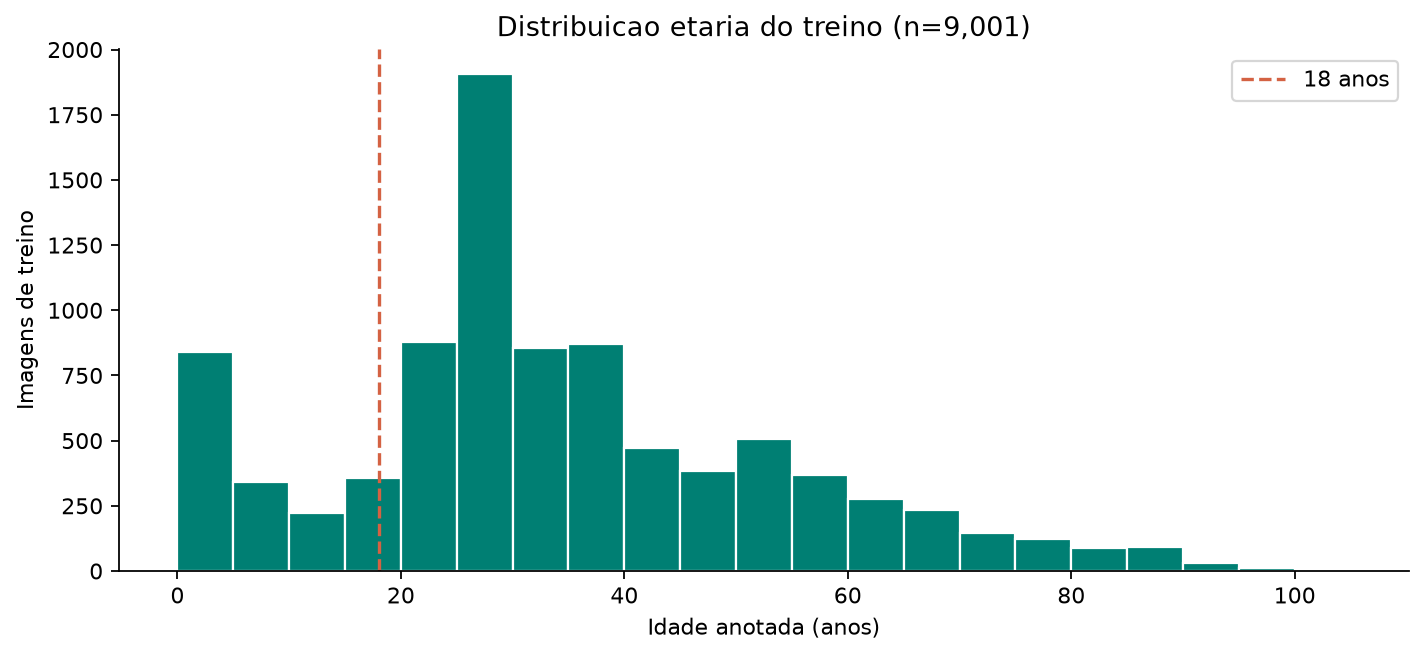

O treino tem 9001 imagens, idade media 33.13, mediana 29 e intervalo 1 a 100 anos. Menores de 18 somam 1620 (18.0%). A distribuicao nao e uniforme; MAE global pode ocultar erros nas idades jovens. Idades extremas validas foram mantidas dentro do recorte, sem remocao por serem raras.

In [3]:
finding = findings[0]
display(Image(filename=str(ROOT / 'reports/task04/figures' / finding['filename'])))
display(Markdown(finding['interpretation']))

## 2. Balanceamento por limiar

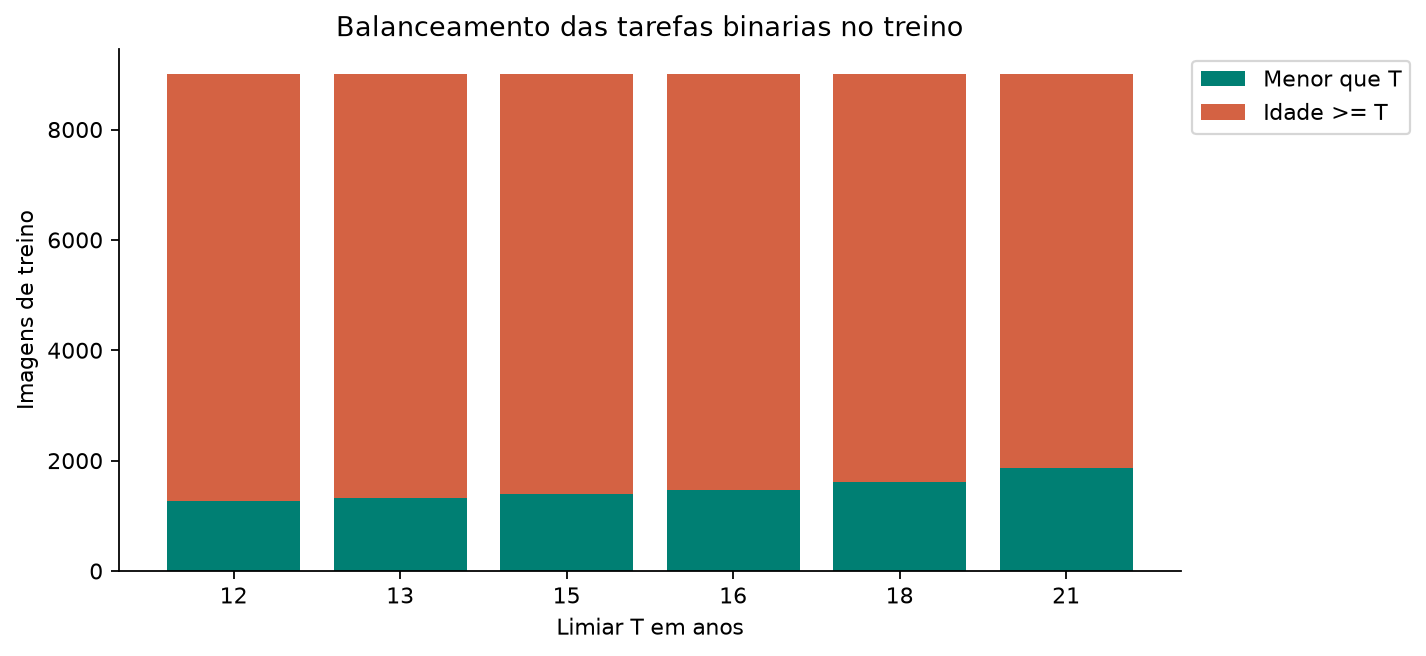

Proporcoes positivas no treino: <12: 14.0%, <13: 14.6%, <15: 15.6%, <16: 16.3%, <18: 18.0%, <21: 20.8%. A classe positiva muda com T; as seis tarefas nao sao independentes. A amostragem por idade do protocolo sera aplicada apenas no treino. Validacao e teste nao recebem sobreamostragem nem pesos de treino.

In [4]:
finding = findings[1]
display(Image(filename=str(ROOT / 'reports/task04/figures' / finding['filename'])))
display(Markdown(finding['interpretation']))

## 3. Representacao demografica anotada

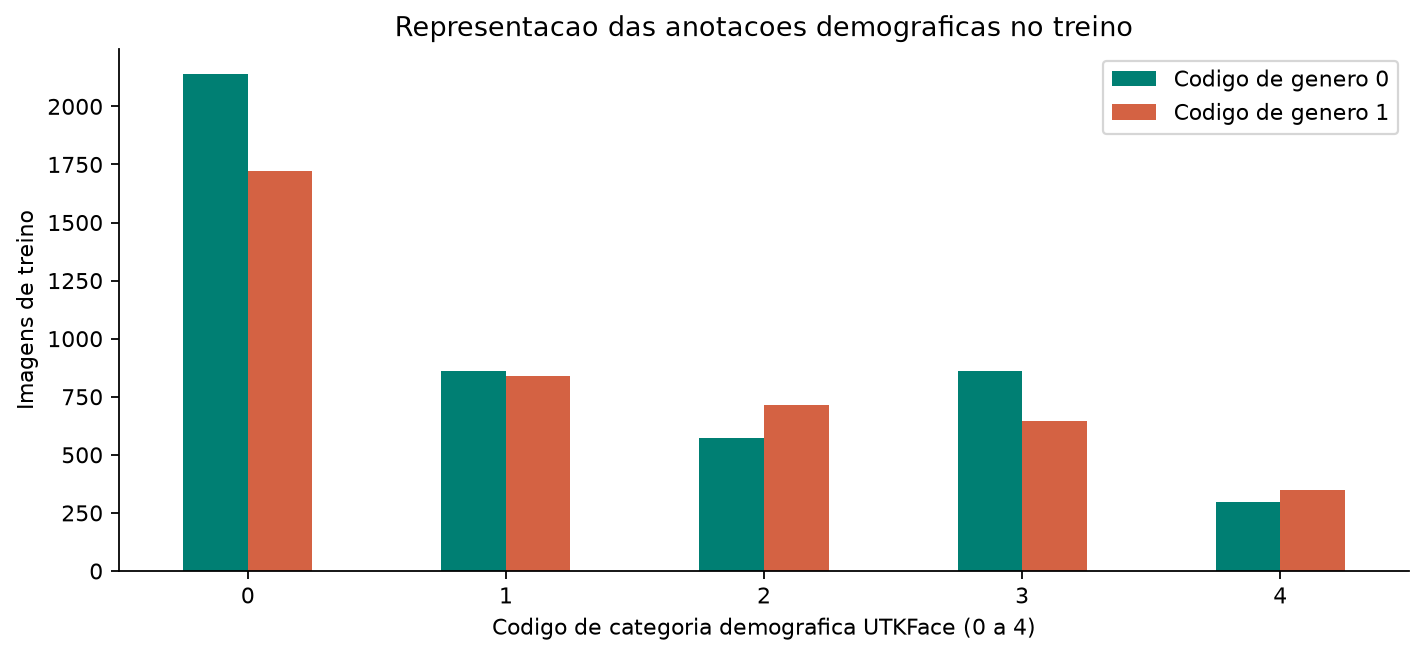

A categoria 0 tem 3859 registros e a categoria 4 tem 649. Os codigos descrevem os rotulos binarios/de categorias do dataset, nao identidade de genero ou etnia verificada. Nao entram como atributos preditores. O desbalanceamento exige cautela ao generalizar; esta figura nao mede equidade do modelo, pois nenhum modelo foi treinado.

In [5]:
finding = findings[2]
display(Image(filename=str(ROOT / 'reports/task04/figures' / finding['filename'])))
display(Markdown(finding['interpretation']))

## 4. Variacao de qualidade visual

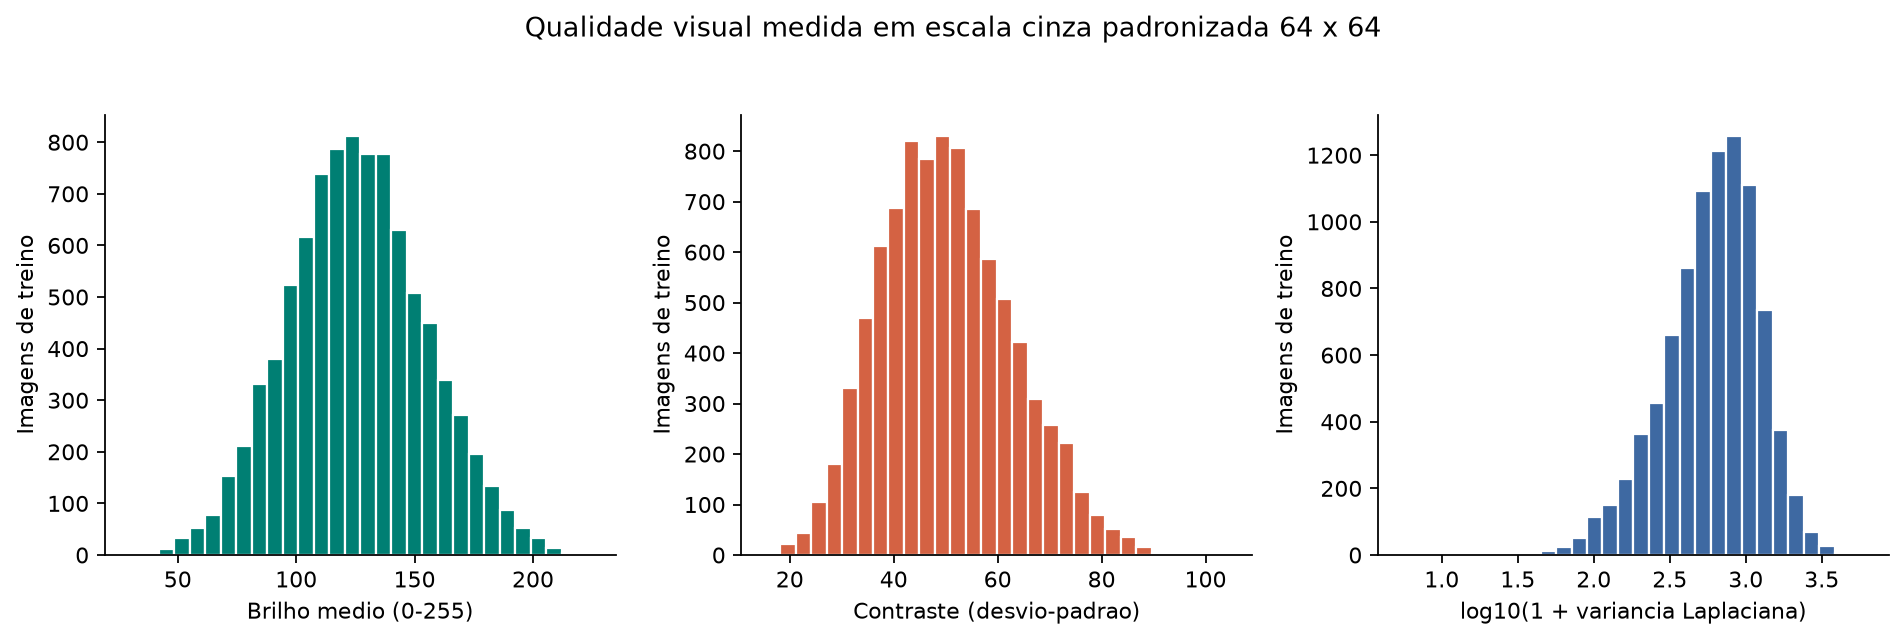

Medianas de brilho 124.9, contraste 49.5 e variancia Laplaciana 651.8. As medidas usam o mesmo tamanho 64 x 64, para comparar imagens em condicoes consistentes. Elas nao provam qualidade facial ou idade correta. Imagens escuras, claras ou pouco nitidas nao foram excluidas por limiar arbitrario, evitando facilitar artificialmente o problema.

In [6]:
finding = findings[3]
display(Image(filename=str(ROOT / 'reports/task04/figures' / finding['filename'])))
display(Markdown(finding['interpretation']))

## 5. Formato e resolucao

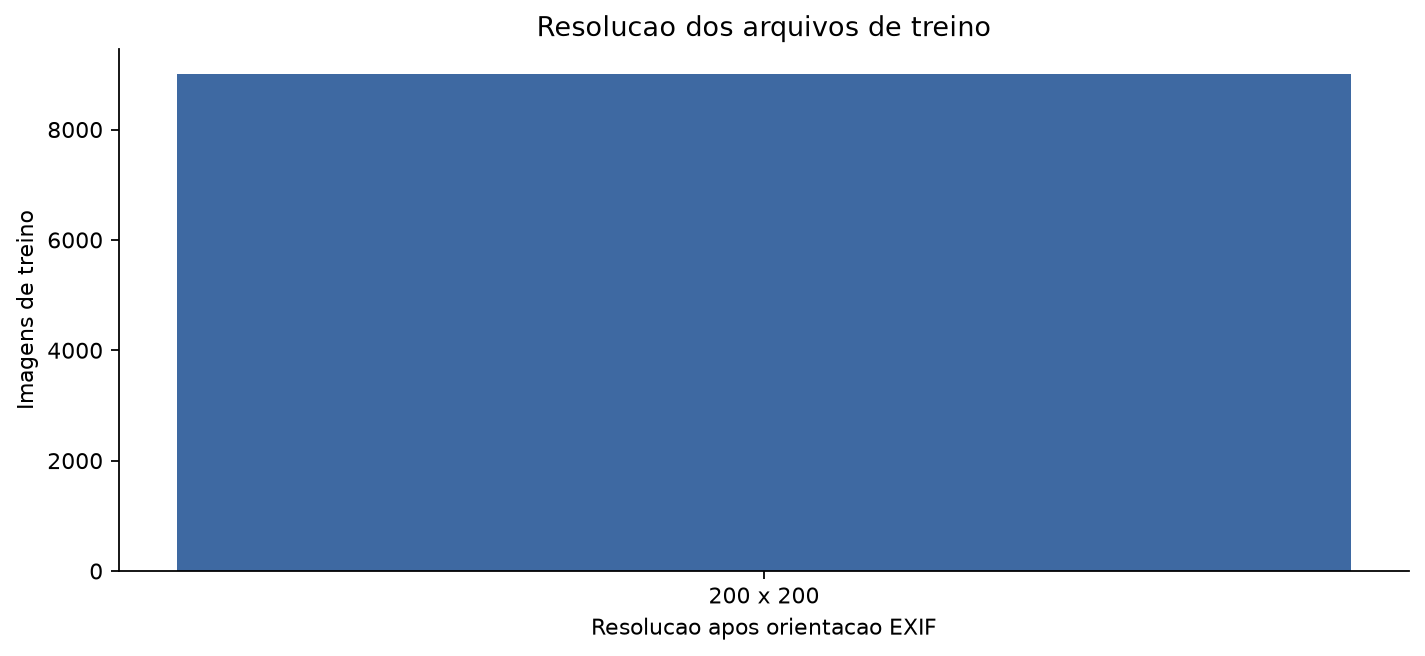

Foram observadas 1 resolucoes no treino e modos originais {'RGB': 9001}. A conversao RGB e a orientacao EXIF sao deterministicas. O FaRL ainda exigira seu preprocessamento oficial 224 x 224; aumentar uma imagem pequena nao recupera detalhes perdidos.

In [7]:
finding = findings[4]
display(Image(filename=str(ROOT / 'reports/task04/figures' / finding['filename'])))
display(Markdown(finding['interpretation']))

## 6. Fluxo de exclusao e amostragem

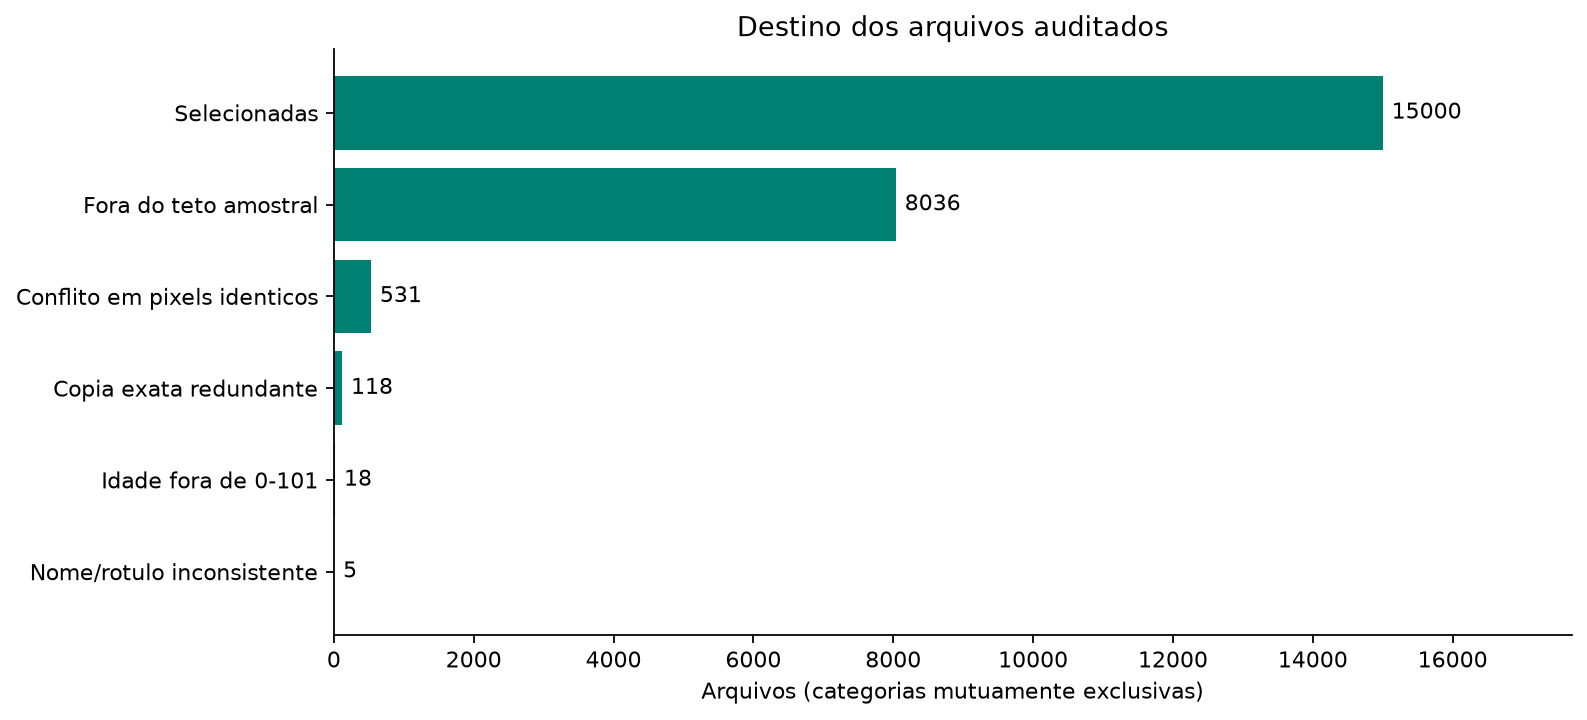

Todos os 23708 arquivos foram auditados; 23708 decodificaram. Foram excluidos 5 nomes inconsistentes, 18 idades fora do recorte, 118 copias exatas redundantes e 531 imagens de grupos exatos com rotulos conflitantes. Outros 8036 registros elegiveis ficaram fora somente pelo teto de custo, nao por erro de modelo. As exclusoes conservadoras podem alterar a distribuicao e devem constar como limitacao da reproducao reduzida.

In [8]:
finding = findings[5]
display(Image(filename=str(ROOT / 'reports/task04/figures' / finding['filename'])))
display(Markdown(finding['interpretation']))

## 7. Suporte e precisao do alvo de recall

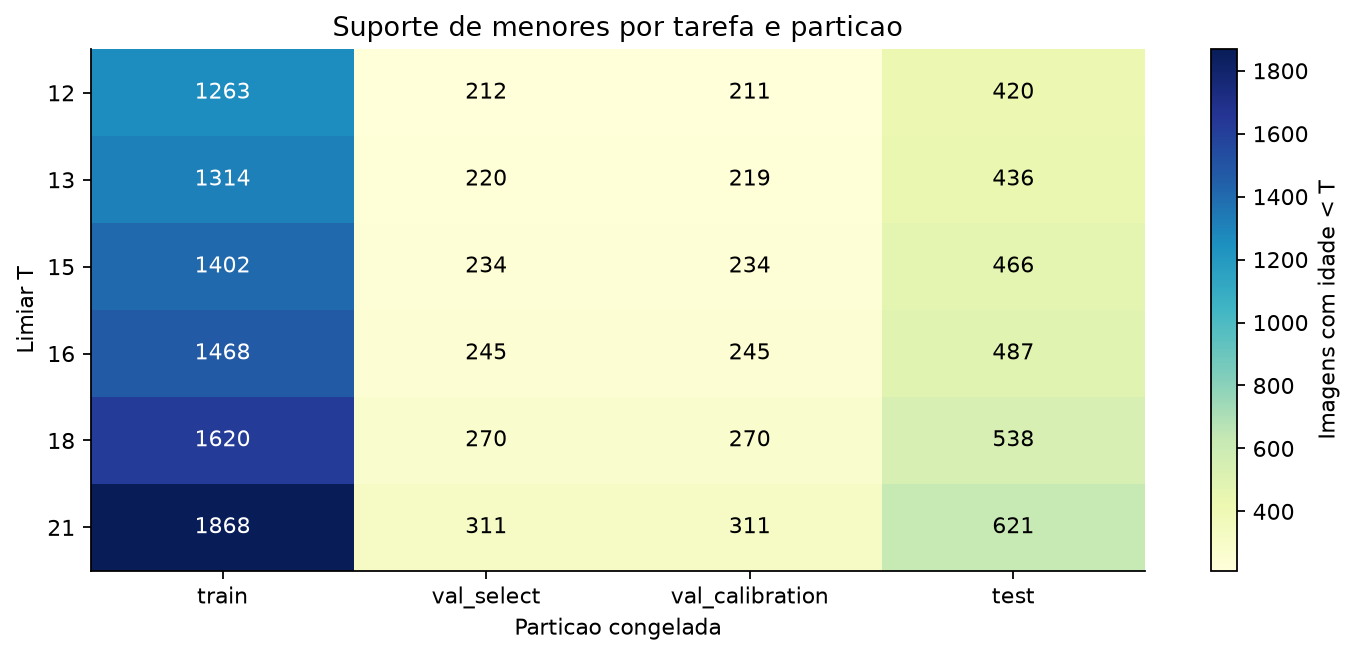

O menor suporte positivo e 211 na calibracao e 420 no teste. Um unico falso adulto muda a FNR em 1/n; recall de 0,99 nao pode ser tratado como garantia. A tabela usa somente contagens de suporte previstas para auditar a particao, nao escolhas de modelo pelo teste. Dependencia por pessoa pode reduzir o tamanho efetivo da amostra; a separacao por identidade nao foi comprovada.

In [9]:
finding = findings[6]
display(Image(filename=str(ROOT / 'reports/task04/figures' / finding['filename'])))
display(Markdown(finding['interpretation']))

## 8. Validacao cruzada sem romper grupos

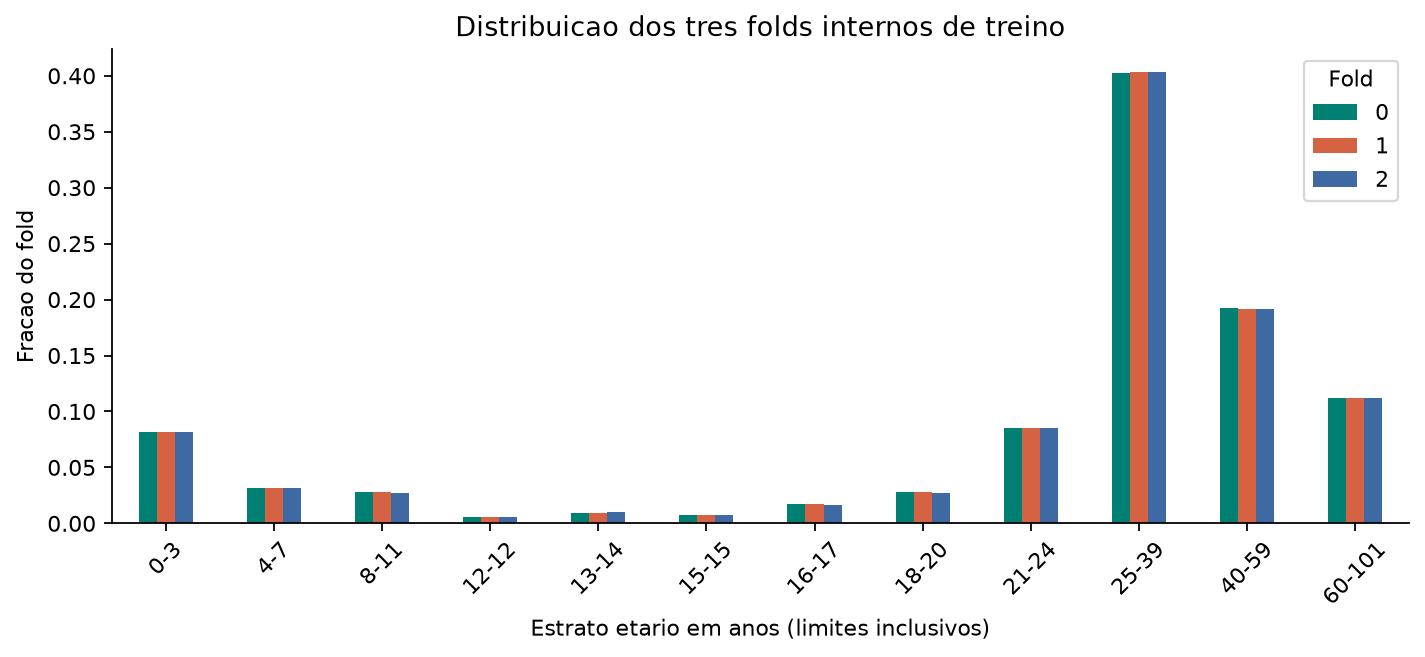

Tamanhos dos folds internos: {0: 3001, 1: 3000, 2: 3000}. Todos sao subconjuntos exclusivos do treino e grupos de duplicatas nao cruzam folds. Pequenas diferencas entre as proporcoes sao esperadas ao preservar grupos inteiros. Normalizacao, amostragem e tuning futuros deverao ser ajustados dentro de cada fold, sem usar seus exemplos de avaliacao.

In [10]:
finding = findings[7]
display(Image(filename=str(ROOT / 'reports/task04/figures' / finding['filename'])))
display(Markdown(finding['interpretation']))

## Conclusao e proximos passos

Ha desbalanceamento etario/demografico e rotulos conflitantes em imagens identicas. O recorte preserva grupos e e limitado a pesquisa neste dataset. Nenhuma metrica de modelo foi estimada. Preprocessamento: RGB/EXIF deterministico, nao imputar alvos, nao excluir por brilho/nitidez, escalonar e balancear somente dentro do treino/fold.

Proxima task: extracao congelada de features, sem alterar os manifests nem consultar o teste. Os resultados nao justificam verificacao etaria real ou controle de acesso.